In [167]:
import numpy as np
import pandas as pd

In [168]:
train_df = pd.read_csv('Project Data/lending_club_train.csv')
test_df = pd.read_csv('Project Data/lending_club_test.csv')

In [169]:
print("--- Train Data Head ---")
display(train_df.head())

print("\n--- Test Data Head ---")
display(test_df.head())

--- Train Data Head ---


,issue_d,sub_grade,term,home_ownership,fico_range_low,total_acc,pub_rec,revol_util,annual_inc,int_rate,...,pub_rec_bankruptcies,addr_state,initial_list_status,fico_range_high,revol_bal,id,open_acc,emp_length,loan_status,time_to_earliest_cr_line
0,2014-01-01,D1,60 months,MORTGAGE,660.0,18.0,0.0,86.8,40440.0,16.99,...,0.0,AR,f,664.0,17264.0,11024793,11.0,2.0,1,478656.0
1,2014-01-01,C4,60 months,MORTGAGE,740.0,26.0,0.0,103.5,59000.0,15.61,...,0.0,VT,f,744.0,6725.0,10596078,8.0,3.0,1,541728.0
2,2014-01-01,A4,36 months,RENT,700.0,47.0,0.0,11.4,40000.0,7.90,...,0.0,TX,w,704.0,7613.0,10775616,27.0,1.0,1,657590.4
3,2014-01-01,D1,60 months,MORTGAGE,665.0,26.0,0.0,56.2,70000.0,16.99,...,0.0,IN,f,669.0,14173.0,10765610,9.0,11.0,1,328838.4
4,2014-01-01,C3,36 months,MORTGAGE,700.0,15.0,1.0,67.1,120000.0,14.98,...,0.0,LA,f,704.0,2549.0,10794837,8.0,2.0,1,305164.8



--- Test Data Head ---


,issue_d,sub_grade,term,home_ownership,fico_range_low,total_acc,pub_rec,revol_util,annual_inc,int_rate,...,pub_rec_bankruptcies,addr_state,initial_list_status,fico_range_high,revol_bal,id,open_acc,emp_length,loan_status,time_to_earliest_cr_line
0,2016-07-01,A4,36 months,MORTGAGE,830.0,13.0,0.0,12.0,105682.0,7.99,...,0.0,TX,w,834.0,4266.0,84759443,5.0,11.0,1.0,789004.8
1,2016-07-01,B5,36 months,RENT,660.0,25.0,0.0,59.4,68000.0,11.49,...,0.0,CA,w,664.0,6944.0,84433407,11.0,6.0,1.0,294624.0
2,2016-07-01,D2,36 months,MORTGAGE,660.0,17.0,1.0,40.9,75000.0,17.99,...,1.0,AZ,w,664.0,5528.0,84646007,6.0,3.0,1.0,349747.2
3,2016-07-01,A1,36 months,RENT,740.0,36.0,0.0,27.7,114000.0,5.32,...,0.0,CA,w,744.0,25912.0,84477434,16.0,1.0,1.0,691632.0
4,2016-07-01,C4,60 months,MORTGAGE,680.0,14.0,0.0,44.3,47000.0,14.49,...,0.0,OH,w,684.0,4205.0,84525798,12.0,2.0,0.0,591667.2


In [170]:
# Converting "issue_d" to datetime format
train_df['issue_d_dt'] = pd.to_datetime(train_df['issue_d'], errors='coerce')

In [171]:
# Filtering for 2016 data
train_2016 = train_df[train_df['issue_d_dt'].dt.year == 2016].copy()
print(f"Original training rows: {train_df.shape[0]}")
print(f"Filtered 2016 training rows: {train_2016.shape[0]}")
print(f"Months included in 2016 train set: {sorted(train_2016['issue_d_dt'].dt.month.unique())}")

Original training rows: 236846
Filtered 2016 training rows: 53844
Months included in 2016 train set: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]


In [172]:
# Doing the same for the test data
test_df['issue_d_dt'] = pd.to_datetime(test_df['issue_d'], errors='coerce')
test_2016 = test_df[test_df['issue_d_dt'].dt.year == 2016].copy()
print(f"Original test rows: {test_df.shape[0]}")
print(f"Filtered 2016 test rows: {test_2016.shape[0]}")
print(f"Months included in 2016 test set: {sorted(test_2016['issue_d_dt'].dt.month.unique())}")

Original test rows: 95019
Filtered 2016 test rows: 31333
Months included in 2016 test set: [np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]


In [173]:
# Checking for nulls
print("--- TRAIN NULL % ---")
train_nulls = (train_2016.isnull().sum() / len(train_2016) * 100).round(2)
print(train_nulls[train_nulls > 0].sort_values(ascending=False))

print("\n--- TEST NULL % ---")
test_nulls = (test_2016.isnull().sum() / len(test_2016) * 100).round(2)
print(test_nulls[test_nulls > 0].sort_values(ascending=False))

--- TRAIN NULL % ---
Series([], dtype: float64)

--- TEST NULL % ---
Series([], dtype: float64)


In [174]:
# Map sub_grade (A1..G5) to an ordinal 1..35 instead of one-hot encoding it
grades = [f"{g}{n}" for g in "ABCDEFG" for n in range(1, 6)]
grade_map = {g: i + 1 for i, g in enumerate(grades)}
train_2016['sub_grade'] = train_2016['sub_grade'].str.strip().map(grade_map)
test_2016['sub_grade'] = test_2016['sub_grade'].str.strip().map(grade_map)

In [175]:
# 1. Define columns to drop (IDs, dates, and data leakage columns)
cols_to_drop = ['id', 'issue_d', 'issue_d_dt', 'loan_status', 'fico_range_low', 'installment']

# 2. Separate the target variable (int_rate) from the feature sets
train_y = train_2016['int_rate']
test_y = test_2016['int_rate']

train_features = train_2016.drop(columns=cols_to_drop + ['int_rate'])
test_features = test_2016.drop(columns=cols_to_drop + ['int_rate'])

# # 3. Combine temporarily to ensure One-Hot Encoding creates identical columns for both
# combined_features = pd.concat([train_features, test_features], axis=0)
# combined_encoded = pd.get_dummies(combined_features, drop_first=True)

# 3. One-Hot Encode each set separately)
train_encoded = pd.get_dummies(train_features, drop_first=True, dtype=float)
test_encoded = pd.get_dummies(test_features, drop_first=True, dtype=float)

# # 4. Split them back apart into train and test sets
# train_encoded = combined_encoded.iloc[:len(train_2016)]
# test_encoded = combined_encoded.iloc[len(train_2016):]

# 4. Align test to the TRAIN columns: categories unseen in train (e.g. home_ownership_ANY)
#    are dropped, and dummies that exist only in train are added as 0
test_encoded = test_encoded.reindex(columns=train_encoded.columns, fill_value=0.0)

# Quick check on the final shapes
print("Train features shape:", train_encoded.shape)
print("Test features shape:", test_encoded.shape)

Train features shape: (53844, 81)
Test features shape: (31333, 81)


In [176]:
# ---------------- Baseline regression tree (default settings) ----------------
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def report(name, model):
    """Fit on 2016 train, score on both train and 2016 test."""
    model.fit(train_encoded, train_y)
    results = {}
    for label, X, y in [("train", train_encoded, train_y), ("test", test_encoded, test_y)]:
        pred = model.predict(X)
        results[label] = {
            "R2": r2_score(y, pred),
            "RMSE": mean_squared_error(y, pred) ** 0.5,
            "MAE": mean_absolute_error(y, pred),
        }
    print(f"\n--- {name} ---")
    print(pd.DataFrame(results).T.round(4))
    return model

# 1. Reference point: always predict the training mean
report("Mean-predictor reference", DummyRegressor(strategy="mean"))

# 2. Baseline: regression tree under default settings
baseline_tree = report("Baseline regression tree (defaults)", DecisionTreeRegressor(random_state=42))
print("Leaves:", baseline_tree.get_n_leaves(), " Depth:", baseline_tree.get_depth())

# 3. Which features does the tree rely on?
importances = pd.Series(baseline_tree.feature_importances_, index=train_encoded.columns)
print("\nTop 10 feature importances:")
print(importances.sort_values(ascending=False).head(10).round(4))


--- Mean-predictor reference ---
           R2    RMSE     MAE
train  0.0000  4.9115  3.8941
test  -0.0572  5.0842  3.7231



--- Baseline regression tree (defaults) ---
           R2   RMSE     MAE
train  1.0000  0.000  0.0000
test   0.9493  1.113  0.7065
Leaves: 15525  Depth: 69

Top 10 feature importances:
sub_grade                   0.9935
annual_inc                  0.0010
time_to_earliest_cr_line    0.0005
revol_bal                   0.0005
fico_range_high             0.0005
revol_util                  0.0005
dti                         0.0005
loan_amnt                   0.0003
open_acc                    0.0003
total_acc                   0.0003
dtype: float64


max_leaf_nodes  min_impurity_decrease  leaves  depth  train_R2  test_R2  test_RMSE  test_MAE  cv_RMSE
             5                 0.0000       5      3    0.9186   0.8762     1.7399    1.3795   1.4026
             5                 0.0001       5      3    0.9186   0.8762     1.7399    1.3795   1.4026
             5                 0.0010       5      3    0.9186   0.8762     1.7399    1.3795   1.4026
             5                 0.0100       5      3    0.9186   0.8762     1.7399    1.3795   1.4026
             5                 0.1000       5      3    0.9186   0.8762     1.7399    1.3795   1.4026
            10                 0.0000      10      4    0.9741   0.9349     1.2612    0.8690   0.7854
            10                 0.0001      10      4    0.9741   0.9349     1.2612    0.8690   0.7854
            10                 0.0010      10      4    0.9741   0.9349     1.2612    0.8690   0.7854
            10                 0.0100      10      4    0.9741   0.9349     1.2612

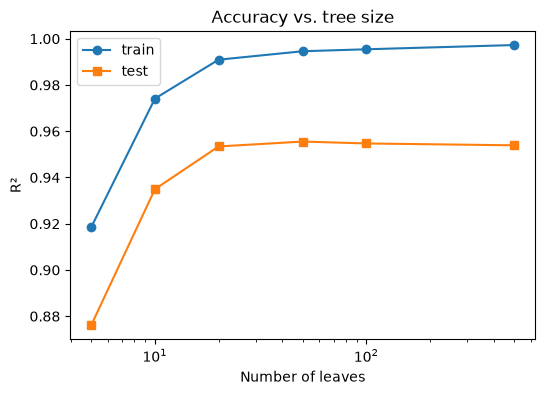

In [177]:
# ---------------- Tuning: max_leaf_nodes x min_impurity_decrease ----------------
import itertools
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score

leaf_grid = [5, 10, 20, 50, 100, 500, None]          # None = no limit (default)
impurity_grid = [0.0, 0.0001, 0.001, 0.01, 0.1]       # 0.0 = default

# 5-fold CV on the 2016 TRAIN data only (shuffled, so each fold mixes Jan-Jun loans)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid_rows = []
for max_leaves, min_dec in itertools.product(leaf_grid, impurity_grid):
    tree = DecisionTreeRegressor(max_leaf_nodes=max_leaves,
                                 min_impurity_decrease=min_dec,
                                 random_state=42)
    # CV score (negative RMSE -> flip sign), computed without touching the test set
    cv_rmse = -cross_val_score(tree, train_encoded, train_y, cv=cv,
                               scoring="neg_root_mean_squared_error").mean()

    tree.fit(train_encoded, train_y)
    p_tr, p_te = tree.predict(train_encoded), tree.predict(test_encoded)
    grid_rows.append({
        "max_leaf_nodes": max_leaves if max_leaves is not None else "None",
        "min_impurity_decrease": min_dec,
        "leaves": tree.get_n_leaves(),
        "depth": tree.get_depth(),
        "train_R2": r2_score(train_y, p_tr),
        "test_R2": r2_score(test_y, p_te),
        "test_RMSE": mean_squared_error(test_y, p_te) ** 0.5,
        "test_MAE": mean_absolute_error(test_y, p_te),
        "cv_RMSE": cv_rmse,
    })

grid_results = pd.DataFrame(grid_rows)
pd.set_option("display.width", 200)
print(grid_results.round(4).to_string(index=False))

# Pick the setting using CV (lowest cv_RMSE), then report its test accuracy
best = grid_results.loc[grid_results["cv_RMSE"].idxmin()]
print("\nBest setting by cross-validation:")
print(best.to_frame().T.round(4).to_string(index=False))

# Plot: effect of tree size on accuracy (min_impurity_decrease = 0)
curve = grid_results[(grid_results["min_impurity_decrease"] == 0.0)
                     & (grid_results["max_leaf_nodes"] != "None")]
plt.figure(figsize=(6, 4))
plt.plot(curve["leaves"], curve["train_R2"], "o-", label="train")
plt.plot(curve["leaves"], curve["test_R2"], "s-", label="test")
plt.xscale("log"); plt.xlabel("Number of leaves"); plt.ylabel("R²")
plt.title("Accuracy vs. tree size"); plt.legend()
plt.show()

--- Test accuracy: default vs tuned ---
                  default (15525 leaves)  tuned (34 leaves)
R2                                0.9493             0.9552
RMSE                              1.1130             1.0462
MAE                               0.7065             0.7099
bias (avg error)                 -0.6855            -0.6914
within 0.5pp                      0.4722             0.4710
within 1pp                        0.8502             0.8435
within 2pp                        0.9394             0.9321

--- Tuned tree: error by grade letter ---
           n  actual   bias    MAE
grade                             
A       4068   7.219 -0.338  0.338
B      10330  10.476 -0.425  0.462
C      10190  14.049 -0.487  0.501
D       4392  18.747 -1.004  1.016
E       1554  24.077 -2.890  2.890
F        621  27.571 -2.798  2.798
G        178  29.780 -1.720  1.720

--- Tuned tree: error by month ---
          n  actual   bias    MAE
month                            
7      5663  13.49

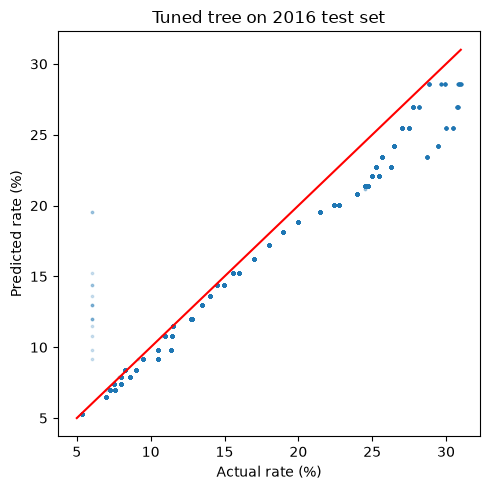

In [178]:
# ---------------- Accuracy analysis: default tree vs tuned tree ----------------
# Rebuild the tuned tree from the CV-best row of the grid
best_leaves = None if best["max_leaf_nodes"] == "None" else int(best["max_leaf_nodes"])
best_min_dec = float(best["min_impurity_decrease"])

default_tree = DecisionTreeRegressor(random_state=42).fit(train_encoded, train_y)
tuned_tree = DecisionTreeRegressor(max_leaf_nodes=best_leaves,
                                   min_impurity_decrease=best_min_dec,
                                   random_state=42).fit(train_encoded, train_y)

def accuracy(y, p):
    e = p - y                                   # predicted - actual
    return {"R2": r2_score(y, p),
            "RMSE": mean_squared_error(y, p) ** 0.5,
            "MAE": mean_absolute_error(y, p),
            "bias (avg error)": e.mean(),
            "within 0.5pp": (abs(e) <= 0.5).mean(),
            "within 1pp": (abs(e) <= 1).mean(),
            "within 2pp": (abs(e) <= 2).mean()}

pred_default = default_tree.predict(test_encoded)
pred_tuned = tuned_tree.predict(test_encoded)

print("--- Test accuracy: default vs tuned ---")
print(pd.DataFrame({
    f"default ({default_tree.get_n_leaves()} leaves)": accuracy(test_y, pred_default),
    f"tuned ({tuned_tree.get_n_leaves()} leaves)": accuracy(test_y, pred_tuned),
}).round(4))

# Where does the tuned tree make its errors?
res = pd.DataFrame({"actual": test_y, "pred": pred_tuned})
res["err"] = res["pred"] - res["actual"]
res["grade"] = ((test_2016["sub_grade"] - 1) // 5).map(dict(enumerate("ABCDEFG")))  # rank 1-35 -> A..G
res["month"] = test_2016["issue_d_dt"].dt.month

def error_summary(g):
    return g.agg(n=("err", "size"), actual=("actual", "mean"),
                 bias=("err", "mean"), MAE=("err", lambda s: s.abs().mean()))

print("\n--- Tuned tree: error by grade letter ---")
print(error_summary(res.groupby("grade")).round(3))
print("\n--- Tuned tree: error by month ---")
print(error_summary(res.groupby("month")).round(3))

# What does the tuned tree rely on?
tuned_importances = pd.Series(tuned_tree.feature_importances_, index=train_encoded.columns)
print("\n--- Tuned tree: top 8 feature importances ---")
print(tuned_importances.sort_values(ascending=False).head(8).round(4))

# Predicted vs actual (points on the red line = perfect prediction)
plt.figure(figsize=(5, 5))
plt.scatter(res["actual"], res["pred"], s=3, alpha=0.2)
plt.plot([5, 31], [5, 31], "r")
plt.xlabel("Actual rate (%)"); plt.ylabel("Predicted rate (%)")
plt.title("Tuned tree on 2016 test set")
plt.tight_layout(); plt.show()

In [189]:
best_tree = DecisionTreeRegressor(
    max_leaf_nodes=50, min_impurity_decrease=0.001, random_state=42
)
best_tree.fit(train_encoded, train_y)

print(f"Leaves: {best_tree.get_n_leaves()}")
print(f"Depth:  {best_tree.get_depth()}")

# Print the full text tree down to its true depth of 7
print(export_text(best_tree, feature_names=list(train_encoded.columns)))

Leaves: 34
Depth:  7
|--- sub_grade <= 13.50
|   |--- sub_grade <= 7.50
|   |   |--- sub_grade <= 3.50
|   |   |   |--- sub_grade <= 1.50
|   |   |   |   |--- value: [5.32]
|   |   |   |--- sub_grade >  1.50
|   |   |   |   |--- sub_grade <= 2.50
|   |   |   |   |   |--- value: [6.50]
|   |   |   |   |--- sub_grade >  2.50
|   |   |   |   |   |--- value: [6.99]
|   |   |--- sub_grade >  3.50
|   |   |   |--- sub_grade <= 5.50
|   |   |   |   |--- sub_grade <= 4.50
|   |   |   |   |   |--- value: [7.42]
|   |   |   |   |--- sub_grade >  4.50
|   |   |   |   |   |--- value: [7.92]
|   |   |   |--- sub_grade >  5.50
|   |   |   |   |--- sub_grade <= 6.50
|   |   |   |   |   |--- value: [8.43]
|   |   |   |   |--- sub_grade >  6.50
|   |   |   |   |   |--- value: [9.18]
|   |--- sub_grade >  7.50
|   |   |--- sub_grade <= 10.50
|   |   |   |--- sub_grade <= 8.50
|   |   |   |   |--- value: [9.78]
|   |   |   |--- sub_grade >  8.50
|   |   |   |   |--- sub_grade <= 9.50
|   |   |   |   |   